# Robustez: as tendências sobrevivem à mistura de tipos e ao jornal?

O caderno `incerteza` mostrou que várias mudanças entre os períodos legais **não são sorte da amostra**. Aqui fazemos outra pergunta:
**elas não seriam um efeito de composição?** Duas confusões possíveis:

1. **Mistura de tipos.** Se num período há mais anúncios de fuga e noutro mais de aluguel, parcelas de temas (fuga, serviço doméstico,
   ama de leite) mudam só porque a mistura mudou, não porque os anúncios de cada tipo mudaram.
2. **Fonte.** Parte dos anúncios vem de outros jornais (bibs `094170_01` e `706744`); se eles pesam diferente em cada período, a tendência
   pode ser de jornal, não de época.

Refazemos as **mesmas 9 medidas** do caderno `incerteza` em **quatro visões**:

| Visão | O que é |
|---|---|
| **Bruta** | como no caderno `incerteza` |
| **Ajustada** | a mistura de tipos é igualada entre os períodos (padronização, abaixo) |
| **Só JC** | só o Jornal do Commercio (sem os bibs `094170_01` e `706744`) |
| **Ajustada + JC** | as duas coisas |

**Como se ajusta a mistura.** Cada anúncio recebe um peso = (fatia do seu tipo no corpus todo) ÷ (fatia do seu tipo no seu período), entre os
4 tipos **fuga, aluguel, venda e ama de leite**. Assim, depois de pesar, todos os períodos têm a mesma mistura de tipos e a diferença que sobra
não vem dela. **Anúncios de compra ficam de fora das visões ajustadas** (peso 0). O ajuste vale para as medidas **7, 8 e 9** (parcelas de temas);
as medidas **2 a 6** já são calculadas dentro de um tipo (fuga ou aluguel), então ajustada = bruta e só mudam em "só JC" (mostramos "—" nas colunas
ajustadas). A medida **1** (% de anúncios que são fuga) **é** a própria mistura: não se ajusta, só tem a visão "só JC", e mede o que a **busca achou**.

**n efetivo.** Com pesos, anúncios valem quantidades diferentes e a amostra "vale" menos que o n bruto: `n efetivo = (Σ pesos)² / Σ pesos²`
(com pesos iguais é o próprio n). **⚠ marca n ou n efetivo < 30**: a faixa é larga e frágil. Em "só JC", o período **antes de 1831** fica com poucos
anúncios e quase sempre vem marcado ⚠.

**Bootstrap ponderado.** Sorteamos anúncios com reposição levando o peso junto e recalculamos a média ponderada de cada período (2.000 repetições);
a diferença é último − primeiro período, com o mesmo bootstrap. Para as parcelas ajustadas, a tendência é um **teste de permutação**: dentro de cada tipo
embaralhamos o período entre os anúncios (1.000 vezes) e comparamos a inclinação (mínimos quadrados ponderados da parcela contra o escore do período, 1 a 4).
Nas visões não ajustadas ficam os testes do caderno `incerteza` (Cochran–Armitage nas proporções, Spearman nas contínuas). O p ajustado (Benjamini–Hochberg)
é calculado dentro de cada visão, sobre as medidas que se aplicam a ela.

**"Mantém?"** compara a visão bruta com as outras visões aplicáveis à medida: **mantém** = mesmo sinal e IC da diferença sem zero em todas;
**parcial** = em algumas; **não mantém** = em nenhuma; **frágil** = alguma visão necessária tem n ou n efetivo < 30 no primeiro ou no último período.

Corpus `corp3`, campos `c6`, temas `t5`. Os números dos comentários foram lidos da saída
da própria execução; se o banco mudar, **confira os números de novo**.

> **Cuidado ao ler:** (1) os anúncios vêm de **frases de busca**, não de sorteio; (2) **o bootstrap usa o modelo de temas fixo e não mede a
> instabilidade do LDA** (outra semente poderia reorganizar os temas); (3) os anúncios de um período não são independentes (reanúncios, mesmo dono),
> então as faixas são um pouco otimistas; (4) ajustar a mistura **não elimina** outros vieses (o que a busca achou, mudanças de formato do jornal).

## Preparação: ler o corpus, os campos e os temas

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from hdb import config
from hdb.banco import BancoSupabase
from hdb.categorias import categorias
from hdb.ajustes import (diferenca_ponderada_ic, inclinacao_permutacao, media_ponderada_ic, n_efetivo,
                         pesos_mistura, so_jc)
from hdb.estatistica import bootstrap_ic, cochran_armitage, diferenca_ic, fdr_bh, spearman_tendencia, wilson
from hdb.topicos import nomear

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
banco = BancoSupabase()
db = banco.cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]
MIN_N = 30
MODELO = config.VERSAO_TOPICOS

corpus = pd.DataFrame(banco.anuncios_do_corpus(config.VERSAO_CORPUS))
corpus = corpus[corpus["texto_padrao"].fillna("").str.strip() != ""][["id", "periodo_legal"]]
# campos e texto ORIGINAL (para as marcas no corpo), da view anuncios_completos
extra = ler_tudo(lambda: db.table("anuncios_completos")
                 .select("id,texto,bib,c_tipo,c_sexo,c_idade_min,c_idade_max,c_nacoes,c_recompensa")
                 .in_("versao", list(config.VERSOES_ANUNCIOS)).eq("c_versao", config.VERSAO_CAMPOS).order("id")).drop_duplicates("id")
df = corpus.merge(extra, on="id", how="left")
df["periodo"] = df["periodo_legal"].map(lambda p: periodo_curto(p) if isinstance(p, str) else None)
df = df[df["periodo"].isin(PERIODOS)].copy()
df["idade"] = df[["c_idade_min", "c_idade_max"]].astype(float).mean(axis=1)
tem = lambda s: s.map(lambda v: isinstance(v, list) and len(v) > 0)
# pesos da padronização: sobre o corpus todo e sobre o corpus só do Jornal do Commercio
df["w_aj"] = pesos_mistura(df)
jc_ = so_jc(df)
df["w_ajjc"] = pesos_mistura(jc_).reindex(df.index).fillna(0.0)
print(f"{len(df)} anúncios no corpus {config.VERSAO_CORPUS} com período legal")
if len(df) != 2191:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2191 anúncios e agora são {len(df)}: "
          "confira os números dos textos antes de usar.")

# misturas de temas do modelo da rodada, com os nomes sugeridos (topicos.nomear sobre as 12 palavras de maior peso)
palavras = ler_tudo(lambda: db.table("topico_palavras").select("topico,palavra,peso").eq("versao", MODELO)
                    .order("topico").order("peso", desc=True))
dist = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao").eq("versao", MODELO)
                .order("anuncio_id").order("topico"))
NOMES = nomear({t: g.sort_values("peso", ascending=False)["palavra"].head(12) for t, g in palavras.groupby("topico")})
pivo = dist.pivot(index="anuncio_id", columns="topico", values="proporcao").rename(columns=NOMES)
temas = df.set_index("id")[["periodo", "bib", "c_tipo", "w_aj", "w_ajjc"]].join(pivo, how="inner")
print(f"{len(temas)} anúncios com mistura de temas no modelo {MODELO}")
print("Temas:", "; ".join(f"T{t} {n}" for t, n in NOMES.items()))

def soma_temas(predicado):
    cols = [n for n in pivo.columns if predicado(n)]
    return temas[cols].sum(axis=1) if cols else None   # None = tema ausente neste modelo

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
COR = "#0072B2"

2191 anúncios no corpus corp3 com período legal


2191 anúncios com mistura de temas no modelo t5
Temas: T0 Aluguel de pretos e moleques para todo o serviço; T1 Fuga: nome, idade e dono; T2 Venda com preço e qualidades; T3 Mulheres: lavar, engomar, cozinhar (aluguel e venda); T4 Fuga: roupa levada e nação; T5 Ama de leite


## 1. Tabela resumo: as 9 medidas em quatro visões
Cada célula: valor no **1º → último** período (ver coluna do período no rodapé), diferença último − primeiro com IC de 95%, e o p ajustado da visão.
"—" = a visão não se aplica à medida. ⚠ = n ou n efetivo < 30 no primeiro ou no último período dessa visão. **Mantém?** compara a bruta com as outras visões;
**Sem as frágeis** repete o veredito ignorando as visões marcadas ⚠ (para mostrar o que as visões bem medidas dizem).

In [2]:
VISOES = ["Bruta", "Ajustada", "Só JC", "Ajustada + JC"]
SIGLA = {"Bruta": "bruta", "Ajustada": "aj", "Só JC": "jc", "Ajustada + JC": "ajjc"}
FATOR = lambda tipo: 100 if tipo != "mediana" else 1   # proporções e parcelas em %, idade em anos

def _base(d, serie):
    b = d[["periodo", "bib", "c_tipo", "w_aj", "w_ajjc"]].copy()
    b["v"] = serie.astype(float)
    return b.dropna(subset=["v"])

def _tema(serie):
    if serie is None:
        return None
    b = temas[["periodo", "bib", "c_tipo", "w_aj", "w_ajjc"]].copy()
    b["v"] = serie.astype(float)
    return b

fuga = df[df["c_tipo"] == "fuga"]
alug = df[(df["c_tipo"] == "aluguel") & df["c_sexo"].isin(["f", "m"])]
marcas = fuga["texto"].map(lambda t: len(categorias(t)["marcas"]) > 0 if isinstance(t, str) else False)
SEM_AJ = ("Bruta", "Só JC")
TODAS = tuple(VISOES)

# (nome, tipo, unidade, base, visões aplicáveis)
MEDIDAS = [
    ("1. % de anúncios que são fuga", "prop", "%", _base(df, df["c_tipo"] == "fuga"), SEM_AJ),
    ("2. % de fugas com recompensa", "prop", "%", _base(fuga, fuga["c_recompensa"].fillna(False).astype(bool)), SEM_AJ),
    ("3. % de fugas com nação", "prop", "%", _base(fuga, tem(fuga["c_nacoes"])), SEM_AJ),
    ("4. % de fugas com marcas no corpo", "prop", "%", _base(fuga, marcas), SEM_AJ),
    ("5. Idade mediana dos fugidos (anos)", "mediana", "anos", _base(fuga, fuga["idade"]), SEM_AJ),
    ("6. % feminino nos aluguéis", "prop", "%", _base(alug, alug["c_sexo"] == "f"), SEM_AJ),
    ("7. Parcela dos temas de fuga (%)", "media", "%", _tema(soma_temas(lambda n: n.startswith("Fuga"))), TODAS),
    ("8. Parcela dos temas de serviço doméstico (%)", "media", "%",
     _tema(soma_temas(lambda n: n.startswith("Mulheres: lavar") or n.startswith("Aluguel de pretos e moleques"))), TODAS),
    ("9. Parcela do tema Ama de leite (%)", "media", "%", _tema(soma_temas(lambda n: n == "Ama de leite")), TODAS),
]
nomes_ok = [m[0] for m in MEDIDAS]

def dados_da_visao(base, visao):
    """DataFrame (periodo, v, w, c_tipo) da visão: pesos 1 nas visões sem ajuste; peso 0 sai nas ajustadas."""
    if visao == "Bruta":
        d = base.assign(w=1.0)
    elif visao == "Só JC":
        d = so_jc(base).assign(w=1.0)
    elif visao == "Ajustada":
        d = base.assign(w=base["w_aj"])
    else:
        d = so_jc(base).assign(w=lambda x: x["w_ajjc"])
    return d[d["w"] > 0][["periodo", "v", "w", "c_tipo"]]

def calcular(d, tipo, visao, prim=None, ult=None):
    f = FATOR(tipo)
    ponderado = visao in ("Ajustada", "Ajustada + JC")
    por = {}
    if ponderado:
        est = media_ponderada_ic(d["v"], d["w"], d["periodo"], n=2000)
    for p in PERIODOS:
        x = d[d["periodo"] == p]
        v = x["v"].to_numpy()
        n = len(v)
        neff = n_efetivo(x["w"]) if ponderado else float(n)
        if n == 0:
            e = lo = hi = float("nan")
        elif ponderado:
            e, lo, hi = est[p]
        elif tipo == "prop":
            e, lo, hi = wilson(int(v.sum()), n)
        else:
            e, lo, hi = bootstrap_ic(v, np.median if tipo == "mediana" else np.mean)
        por[p] = {"n": n, "neff": neff, "valor": e * f, "baixo": lo * f, "alto": hi * f, "v": v, "w": x["w"].to_numpy()}
    com_dados = [p for p in PERIODOS if por[p]["n"] > 0]
    if prim is None:
        prim, ult = (com_dados[0], com_dados[-1]) if len(com_dados) >= 2 else (None, None)
    # tendência
    if ponderado:
        _, pval = inclinacao_permutacao(d["periodo"].map(PERIODOS.index) + 1, d["v"], d["w"], d["c_tipo"])
    elif tipo == "prop":
        _, pval = cochran_armitage([int(por[p]["v"].sum()) for p in com_dados], [por[p]["n"] for p in com_dados])
    else:
        _, pval = spearman_tendencia(d["periodo"].map(PERIODOS.index), d["v"])
    # diferença último − primeiro
    if prim is None or por[prim]["n"] == 0 or por[ult]["n"] == 0:
        dif = dlo = dhi = float("nan")
    elif ponderado:
        dif, dlo, dhi = diferenca_ponderada_ic(por[prim]["v"], por[prim]["w"], por[ult]["v"], por[ult]["w"])
    else:
        dif, dlo, dhi = diferenca_ic(por[prim]["v"], por[ult]["v"], np.median if tipo == "mediana" else np.mean)
    return {"por": por, "p": pval, "prim": prim, "ult": ult, "dif": dif * f, "dlo": dlo * f, "dhi": dhi * f}

RES = {}   # RES[medida][visão]
for nome, tipo, unidade, base, aplic in MEDIDAS:
    RES[nome] = {}
    if base is None or base.empty:
        continue
    r0 = calcular(dados_da_visao(base, "Bruta"), tipo, "Bruta")
    RES[nome]["Bruta"] = r0
    for vis in aplic:
        if vis != "Bruta":
            RES[nome][vis] = calcular(dados_da_visao(base, vis), tipo, vis, r0["prim"], r0["ult"])
# p ajustado por visão, sobre as medidas aplicáveis a ela
for vis in VISOES:
    ns = [n for n in nomes_ok if vis in RES[n]]
    for n, pa in zip(ns, fdr_bh([RES[n][vis]["p"] for n in ns])):
        RES[n][vis]["padj"] = float(pa)

def fragil(r):
    return r["prim"] is None or min(r["por"][r["prim"]]["neff"], r["por"][r["ult"]]["neff"]) < MIN_N

def segura(r, rb):
    """Mesmo sinal da bruta e IC da diferença sem zero."""
    return (not np.isnan(r["dif"])) and np.sign(r["dif"]) == np.sign(rb["dif"]) and not (r["dlo"] <= 0 <= r["dhi"])

def mantem(n, ignorar_frageis=False):
    rs = RES[n]
    if not rs:
        return "tema ausente"
    rb = rs["Bruta"]
    outras = [v for v in rs if v != "Bruta"]
    if ignorar_frageis:
        outras = [v for v in outras if not fragil(rs[v])]
        if fragil(rb) or not outras:
            return "—"
    elif fragil(rb) or any(fragil(rs[v]) for v in outras):
        return "frágil"
    if np.isnan(rb["dif"]) or rb["dlo"] <= 0 <= rb["dhi"]:
        return "sem efeito na bruta"
    ok = [segura(rs[v], rb) for v in outras]
    return "mantém" if all(ok) else "parcial" if any(ok) else "não mantém"

nf = lambda x, c=1: "—" if x is None or np.isnan(x) else f"{x:.{c}f}".replace(".", ",")
def pf(x):
    return "—" if x is None or np.isnan(x) else ("<0,001" if x < 0.001 else f"{x:.3f}".replace(".", ","))

def resumo_cel(r):
    if r is None:
        return "—"
    a, b = r["por"][r["prim"]], r["por"][r["ult"]]
    return (f"{nf(a['valor'])} → {nf(b['valor'])}; Δ {nf(r['dif'])} [{nf(r['dlo'])}; {nf(r['dhi'])}]; p aj. {pf(r.get('padj'))}"
            + (" ⚠" if fragil(r) else ""))

linhas = []
for n in nomes_ok:
    rs = RES[n]
    if not rs:
        linhas.append({"Medida": n, **{v: "tema ausente" for v in VISOES}, "n efetivo mín.": "—", "Mantém?": "tema ausente", "Sem as frágeis": "—"})
        continue
    neffs = [min(r["por"][r["prim"]]["neff"], r["por"][r["ult"]]["neff"]) for r in rs.values()]
    linhas.append({"Medida": n, **{v: resumo_cel(rs.get(v)) for v in VISOES},
                   "n efetivo mín.": f"{min(neffs):.0f}" + (" ⚠" if min(neffs) < MIN_N else ""),
                   "Mantém?": mantem(n), "Sem as frágeis": mantem(n, True)})
RESUMO = pd.DataFrame(linhas).set_index("Medida")
r1 = next(iter(r for r in RES[nomes_ok[0]].values()))
print(f"Períodos comparados: 1º = {r1['prim']}, último = {r1['ult']} (os mesmos nas quatro visões). Valores em % (idade em anos).")
pd.set_option("display.max_colwidth", 80)
RESUMO

Períodos comparados: 1º = antes de 1831, último = 1871–1888 (os mesmos nas quatro visões). Valores em % (idade em anos).


,Bruta,Ajustada,Só JC,Ajustada + JC,n efetivo mín.,Mantém?,Sem as frágeis
Medida,,,,,,,
1. % de anúncios que são fuga,"44,7 → 23,9; Δ -20,8 [-29,9; -11,8]; p aj. <0,001",—,"28,8 → 23,9; Δ -4,9 [-17,5; 7,6]; p aj. 0,704",—,59,não mantém,não mantém
2. % de fugas com recompensa,"66,2 → 25,8; Δ -40,4 [-55,0; -25,6]; p aj. <0,001",—,"70,6 → 25,8; Δ -44,8 [-68,3; -19,6]; p aj. <0,001 ⚠",—,17 ⚠,frágil,—
3. % de fugas com nação,"63,2 → 0,0; Δ -63,2 [-75,0; -51,5]; p aj. <0,001",—,"47,1 → 0,0; Δ -47,1 [-70,6; -23,5]; p aj. <0,001 ⚠",—,17 ⚠,frágil,—
4. % de fugas com marcas no corpo,"48,5 → 17,2; Δ -31,3 [-45,6; -16,8]; p aj. <0,001",—,"29,4 → 17,2; Δ -12,2 [-36,3; 9,7]; p aj. 0,190 ⚠",—,17 ⚠,frágil,—
5. Idade mediana dos fugidos (anos),"17,5 → 29,0; Δ 11,5 [4,0; 17,0]; p aj. <0,001 ⚠",—,"14,5 → 29,0; Δ 14,5 [1,2; 22,2]; p aj. 0,005 ⚠",—,4 ⚠,frágil,—
6. % feminino nos aluguéis,"56,2 → 68,9; Δ 12,7 [-11,7; 37,1]; p aj. 0,016 ⚠",—,"33,3 → 68,9; Δ 35,6 [2,3; 65,0]; p aj. 0,005 ⚠",—,9 ⚠,frágil,—
7. Parcela dos temas de fuga (%),"46,3 → 25,2; Δ -21,1 [-28,9; -13,5]; p aj. 0,877","25,5 → 22,9; Δ -2,6 [-10,3; 3,8]; p aj. <0,001","31,7 → 25,2; Δ -6,5 [-17,3; 4,4]; p aj. 0,044","24,1 → 21,8; Δ -2,3 [-12,1; 6,4]; p aj. 0,003",43,não mantém,não mantém
8. Parcela dos temas de serviço doméstico (%),"28,0 → 42,8; Δ 14,8 [8,4; 21,4]; p aj. <0,001","47,9 → 41,6; Δ -6,4 [-15,1; 3,6]; p aj. 0,522","35,5 → 42,8; Δ 7,3 [-2,8; 17,0]; p aj. 0,005","49,2 → 42,5; Δ -6,7 [-18,9; 6,5]; p aj. 0,980",43,não mantém,não mantém
9. Parcela do tema Ama de leite (%),"17,4 → 11,2; Δ -6,1 [-11,1; -1,4]; p aj. <0,001","16,5 → 13,4; Δ -3,2 [-8,2; 1,7]; p aj. 0,200","22,4 → 11,2; Δ -11,2 [-20,0; -2,7]; p aj. 0,002","15,5 → 13,3; Δ -2,3 [-9,4; 4,1]; p aj. 0,732",43,parcial,parcial


**O que mostra (leitura da tabela):** nenhuma das 9 medidas passa em todas as visões, e o motivo muda de grupo para grupo.

- **Parcelas dos temas (medidas 7, 8 e 9): as tendências brutas desaparecem quando se iguala a mistura de tipos.** A parcela dos temas de fuga vai de 46,3% a 25,2% na visão bruta (diferença −21,1), mas na ajustada fica entre 22,9% e 25,7% nos quatro períodos (diferença −2,6, intervalo −10,3 a 3,8). O serviço doméstico vai de 28,0% a 42,8% na bruta (+14,8), mas na ajustada fica entre 41,1% e 47,9% (diferença −6,4, intervalo −15,1 a 3,6): **não sobe**. A ama de leite cai −6,1 na bruta e −3,2 na ajustada (intervalo −8,2 a 1,7). Ou seja, **as mudanças dos temas eram, em boa parte, mudança de quanto de cada tipo a busca achou**, e os temas, neste corpus, acompanham o tipo.
- **% de anúncios que são fuga (medida 1):** a queda de 44,7% para 23,9% **quase some só com o Jornal do Commercio**: 28,8% para 23,9%, diferença −4,9, intervalo −17,5 a 7,6. Boa parte da "queda" vinha de o primeiro período incluir o Diário do Rio, rico em fugas.
- **Medidas dentro de um tipo (2 a 6): a direção se mantém em todas, mas o veredito é "frágil".** Só com o JC, o período antes de 1831 tem só 17 fugas (e 9 aluguéis). A **nação citada** (47,1% para 0,0%, intervalo −70,6 a −23,5) e a **recompensa** (70,6% para 25,8%, intervalo −68,3 a −19,6) excluem zero mesmo com 17 fugas, embora com intervalo largo; as **marcas no corpo** (29,4% para 17,2%, intervalo −36,3 a 9,7) mantêm o sinal mas o intervalo chega a zero. A idade mediana e o % feminino no aluguel têm n pequeno nos extremos.
- **Ama de leite (medida 9) é "parcial":** só com o JC a queda é maior (22,4% para 11,2%, intervalo −20,0 a −2,7), mas nas visões ajustadas some.

**Sobre o p das parcelas ajustadas ser menor que 0,001 com diferença pequena:** o teste de permutação usa a inclinação dos 4 períodos, dominada pelos períodos grandes, e detecta mudanças de 1 a 3 pontos; a diferença entre os extremos usa só o período pequeno e tem intervalo largo. **Significância não é relevância**: o efeito é de poucos pontos percentuais.

## 2. Parcelas dos temas por período nas quatro visões (medidas 7 a 9)
Valor e IC de 95% por período, com o n (e o **n efetivo** entre colchetes nas visões ajustadas). ⚠ = n ou n efetivo < 30.

In [3]:
det = []
for n in nomes_ok[6:]:
    for p in PERIODOS:
        linha = {"Medida": n, "Período": p}
        for v in VISOES:
            r = RES[n].get(v)
            if r is None:
                linha[v] = "—"
                continue
            c = r["por"][p]
            ponderado = v in ("Ajustada", "Ajustada + JC")
            ne = f"n={c['n']}" + (f" [ef. {c['neff']:.0f}]" if ponderado else "")
            linha[v] = "sem anúncios" if c["n"] == 0 else (
                f"{nf(c['valor'])} [{nf(c['baixo'])}; {nf(c['alto'])}] ({ne})" + (" ⚠" if c["neff"] < MIN_N else ""))
        det.append(linha)
pd.DataFrame(det).set_index(["Medida", "Período"])

Bruta                               Ajustada                       Só JC                          Ajustada + JC
Medida                                        Período                                                                                                                                            
7. Parcela dos temas de fuga (%)              antes de 1831   46,3 [39,7; 53,0] (n=152)     25,5 [20,3; 31,6] (n=152 [ef. 85])    31,7 [22,3; 41,9] (n=59)      24,1 [16,5; 34,1] (n=59 [ef. 43])
                                              1831–1850       24,1 [21,2; 26,9] (n=565)    25,7 [22,7; 28,7] (n=548 [ef. 514])   24,3 [21,4; 27,3] (n=556)    24,5 [21,9; 27,5] (n=541 [ef. 502])
                                              1850–1871      20,4 [18,5; 22,4] (n=1085)  24,0 [21,6; 26,2] (n=1069 [ef. 1046])  20,4 [18,5; 22,4] (n=1085)  22,7 [20,6; 24,9] (n=1069 [ef. 1056])
                                              1871–1888       25,2 [21,8; 28,7] (n=389)    22,9 [19,6; 26,1] (n=386 [ef. 366])   25,2 [21,8; 28,7] (n=389)    21,8 [18,8; 24,8] (n=386 [ef. 365])
8. Parcela dos temas de serviço doméstico (%) antes de 1831   28,0 [22,7; 33,5] (n=152)     47,9 [39,2; 55,6] (n=152 [ef. 85])    35,5 [26,8; 45,1] (n=59)      49,2 [36,5; 60,3] (n=59 [ef. 43])
                                              1831–1850       39,0 [36,0; 42,1] (n=565)    41,1 [37,6; 44,5] (n=548 [ef. 514])   38,7 [35,5; 41,7] (n=556)    41,9 [38,4; 45,1] (n=541 [ef. 502])
                                              1850–1871      48,0 [45,7; 50,4] (n=1085)  44,5 [42,2; 46,9] (n=1069 [ef. 1046])  48,0 [45,7; 50,4] (n=1085)  45,5 [43,1; 47,7] (n=1069 [ef. 1056])
                                              1871–1888       42,8 [39,3; 46,6] (n=389)    41,6 [38,0; 45,3] (n=386 [ef. 366])   42,8 [39,3; 46,6] (n=389)    42,5 [39,1; 46,2] (n=386 [ef. 365])
9. Parcela do tema Ama de leite (%)           antes de 1831   17,4 [13,3; 21,7] (n=152)     16,5 [12,7; 20,8] (n=152 [ef. 85])    22,4 [14,5; 31,4] (n=59)      15,5 [10,1; 21,6] (n=59 [ef. 43])
                                              1831–1850       14,4 [12,3; 16,6] (n=565)    13,6 [11,6; 15,6] (n=548 [ef. 514])   14,3 [12,3; 16,3] (n=556)    13,5 [11,5; 15,5] (n=541 [ef. 502])
                                              1850–1871      13,0 [11,5; 14,5] (n=1085)  12,9 [11,6; 14,5] (n=1069 [ef. 1046])  13,0 [11,5; 14,5] (n=1085)  12,9 [11,5; 14,4] (n=1069 [ef. 1056])
                                              1871–1888        11,2 [9,3; 13,3] (n=389)    13,4 [10,6; 16,1] (n=386 [ef. 366])    11,2 [9,3; 13,3] (n=389)    13,3 [10,7; 16,0] (n=386 [ef. 365])

**O que mostra (parcelas dos temas por período):** com a mistura de tipos igualada, as parcelas ficam **quase planas**: fuga 25,5%, 25,7%, 24,0% e 22,9%; serviço doméstico 47,9%, 41,1%, 44,5% e 41,6%; ama de leite 16,5%, 13,6%, 12,9% e 13,4%. O período antes de 1831 tem n efetivo 85 (de 152 anúncios) na visão ajustada e 43 (de 59) com o ajuste mais o JC, por isso seus intervalos são os mais largos. A visão ajustada tira os anúncios de compra (36, sem nenhum antes de 1831).

## 3. Gráficos: uma medida por painel, uma linha por visão
Valor e IC de 95% por período. **Círculo aberto** = n ou n efetivo < 30. Visões que não se aplicam à medida não aparecem.

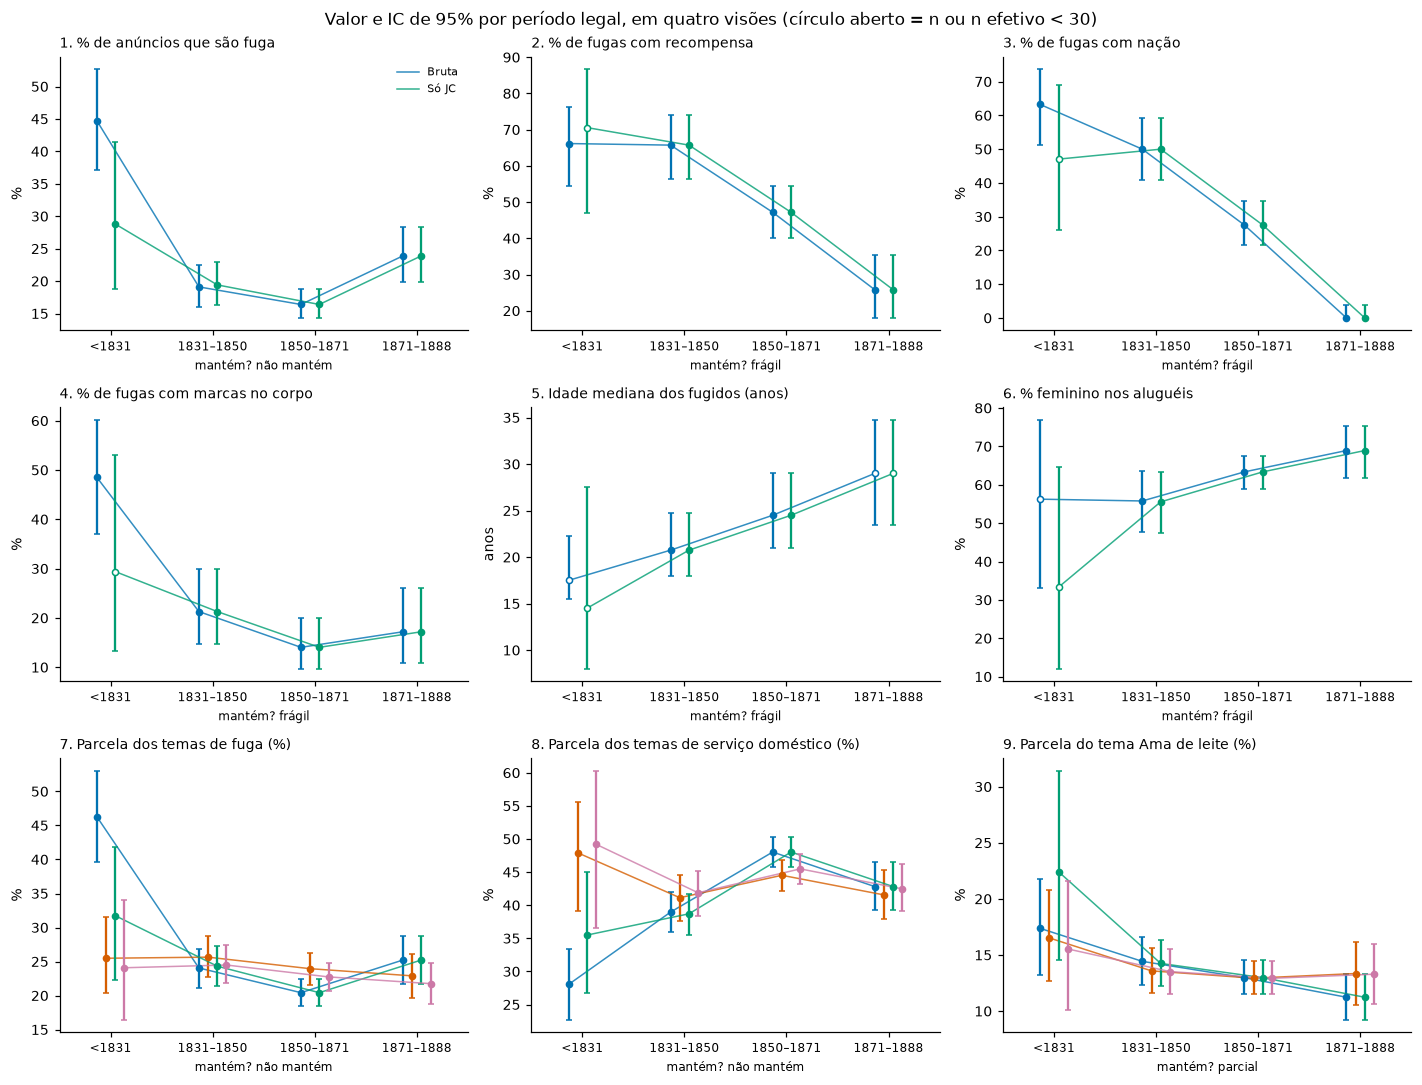

In [4]:
CORES = {"Bruta": "#0072B2", "Ajustada": "#D55E00", "Só JC": "#009E73", "Ajustada + JC": "#CC79A7"}
fig, eixos = plt.subplots(3, 3, figsize=(13, 10))
for ax, n in zip(eixos.ravel(), nomes_ok):
    ax.set_title(n, fontsize=9, loc="left")
    if not RES[n]:
        ax.text(0.5, 0.5, "tema ausente", ha="center", va="center", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        continue
    for k, v in enumerate(VISOES):
        r = RES[n].get(v)
        if r is None:
            continue
        xs, ys, lo, hi = [], [], [], []
        for i, p in enumerate(PERIODOS):
            c = r["por"][p]
            if c["n"] == 0:
                continue
            x = i + (k - 1.5) * 0.09
            xs.append(x); ys.append(c["valor"]); lo.append(c["valor"] - c["baixo"]); hi.append(c["alto"] - c["valor"])
            ax.errorbar(x, c["valor"], yerr=[[max(lo[-1], 0)], [max(hi[-1], 0)]], fmt="o", color=CORES[v], capsize=2, ms=4,
                        mfc="white" if c["neff"] < MIN_N else CORES[v])
        ax.plot(xs, ys, color=CORES[v], lw=1, alpha=0.8, label=v)
    ax.set_xticks(range(len(PERIODOS)))
    ax.set_xticklabels([p.replace("antes de ", "<") for p in PERIODOS], fontsize=8)
    ax.set_ylabel(RES[n]["Bruta"] and MEDIDAS[nomes_ok.index(n)][2]); ax.set_xlim(-0.5, len(PERIODOS) - 0.5)
    ax.set_xlabel(f"mantém? {mantem(n)}", fontsize=8)
eixos[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Valor e IC de 95% por período legal, em quatro visões (círculo aberto = n ou n efetivo < 30)")
fig.tight_layout(); plt.show()

## 4. O que sobrevive e o que não

**O que sobrevive às duas confusões:** a **queda da nação citada nas fugas**, a mais firme (direção mantida só com o JC, intervalo longe de zero mesmo com 17 fugas), e, com menos força, a da **recompensa** e a das **marcas no corpo** (mesmo sinal, mas o intervalo chega a zero só com o JC). Sobem também a idade mediana dos fugidos e a parcela feminina dos aluguéis, **como pistas**.

**O que NÃO sobrevive:** a **queda da fuga** e a **alta do serviço doméstico** como "mudança de tema": igualando a mistura de tipos, os temas quase não mudam. **A parcela de fuga no corpus (medida 1) é, em boa parte, efeito de incluir o Diário do Rio.**

**O que isso diz sobre o método:** o LDA, neste corpus, devolve sobretudo a **separação entre tipos de anúncio**. A mudança de conteúdo **dentro** de um mesmo tipo aparece melhor nos **atributos** (nação, recompensa, marcas, idade) e nas **palavras distintivas** do caderno `mudanca_por_tipo` do que nos temas.

**Cuidado com a base de comparação:** com o JC só, o primeiro período (antes de 1831) é pequeno (17 fugas). Para as medidas dentro de um tipo, **1831–1850 é a base mais estável** (108 fugas no corpus, quase todas do JC). O quadro final de afirmações deve usar essa base quando o primeiro período tiver menos de 30.